In [88]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/diabetic_data.csv")
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [89]:
#Change ? to missiing values.
df = df.replace('?', pd.NA)

#Check how many missing values in each column
df.isna().sum()

#Since we want 0 if not readmitted within 30 and 1 if readmitted, we should change the value. 
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

#Note that we have made >30 readmissions a 0. There are about 35% percent of the data was originally >30 day readmission.
print(df["readmitted"].value_counts())
print(df["readmitted_30"].value_counts())


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted_30
0    90409
1    11357
Name: count, dtype: int64


In [90]:
#Want to make following columns nominal categorical data (w/o order).
category_columns = ['race', 'gender', 'admission_type_id', 'discharge_disposition_id',
                    'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1',
                    'diag_2', 'diag_3', 'A1Cresult', 'metformin', 
                    'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide',
                    'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 
                    'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
                    'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone',
                    'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 
                    ] 

df[category_columns] = df[category_columns].astype('category')

#Ages and weight are in a range like [0-10), Want ordered categorial.
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)'
             , '[60-70)', '[70-80)', '[80-90)', '[90-100)']
df['age'] = pd.Categorical(df['age'], categories=age_order, ordered=True)

weight_order = ['[0-25)', '[25-50)', '[50-75)', '[75-100)', '[100-125)', '[125-150)',
                '[150-175)', '[175-200)', '>200']
df['weight'] = pd.Categorical(df['weight'], categories=weight_order, ordered = True)

#max_glu_serum: Indicates the range of the result or if the test was not taken. About 95% of entries had None.
max_glu_serumlevels = ['Norm', '>200', '>300']
df['max_glu_serum'] = pd.Categorical(df['max_glu_serum'], categories=max_glu_serumlevels, ordered=True)

# Check the data types to make sure its fine. 
print(df.dtypes)

#Make encounter_id and pantient_id strings:
df['encounter_id'] = df['encounter_id'].astype('str')
df['patient_nbr'] = df['patient_nbr'].astype('str')


encounter_id                   int64
patient_nbr                    int64
race                        category
gender                      category
age                         category
weight                      category
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
time_in_hospital               int64
payer_code                  category
medical_specialty           category
num_lab_procedures             int64
num_procedures                 int64
num_medications                int64
number_outpatient              int64
number_emergency               int64
number_inpatient               int64
diag_1                      category
diag_2                      category
diag_3                      category
number_diagnoses               int64
max_glu_serum               category
A1Cresult                   category
metformin                   category
repaglinide                 category
nateglinide                 category
c

time_in_hospital       1.133999
num_lab_procedures    -0.236544
num_procedures         1.316415
num_medications        1.326672
number_outpatient      8.832959
number_emergency      22.855582
number_inpatient       3.614139
number_diagnoses      -0.876746
readmitted_30          2.467071
dtype: float64
Emergency visits distribution count    101766.000000
mean          0.197836
std           0.930472
min           0.000000
50%           0.000000
90%           1.000000
95%           1.000000
99%           3.000000
max          76.000000
Name: number_emergency, dtype: float64


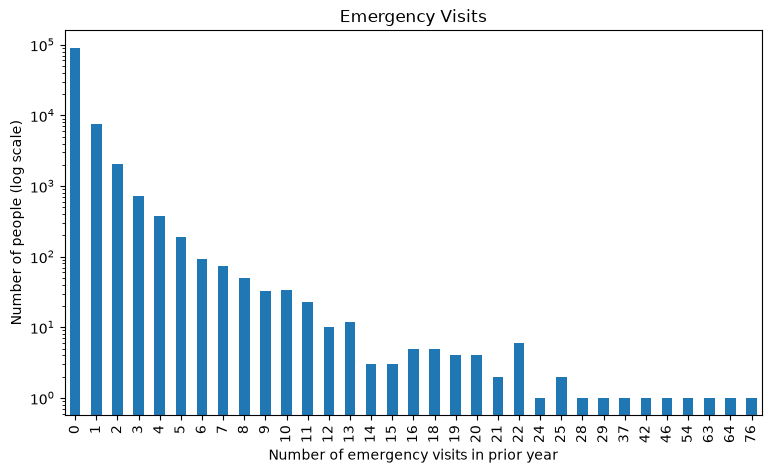

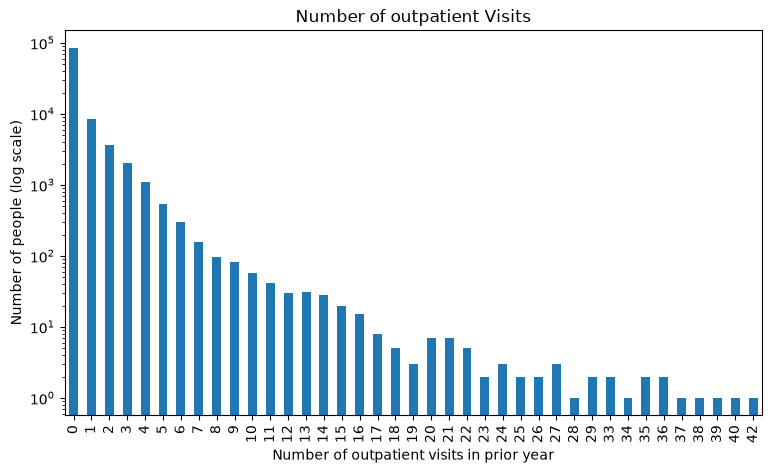

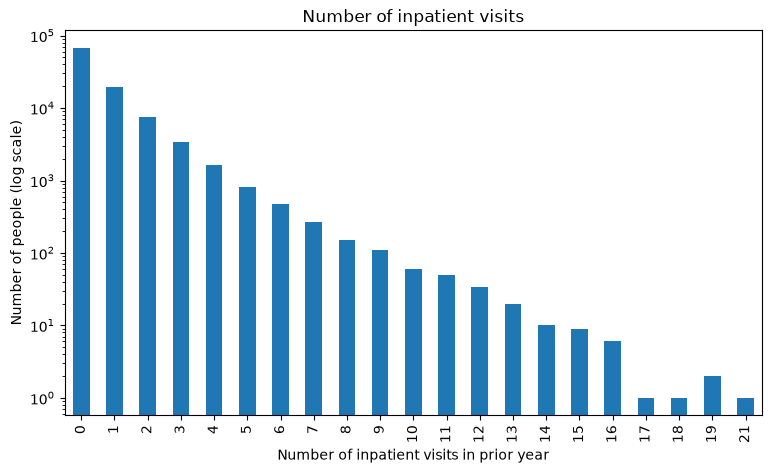

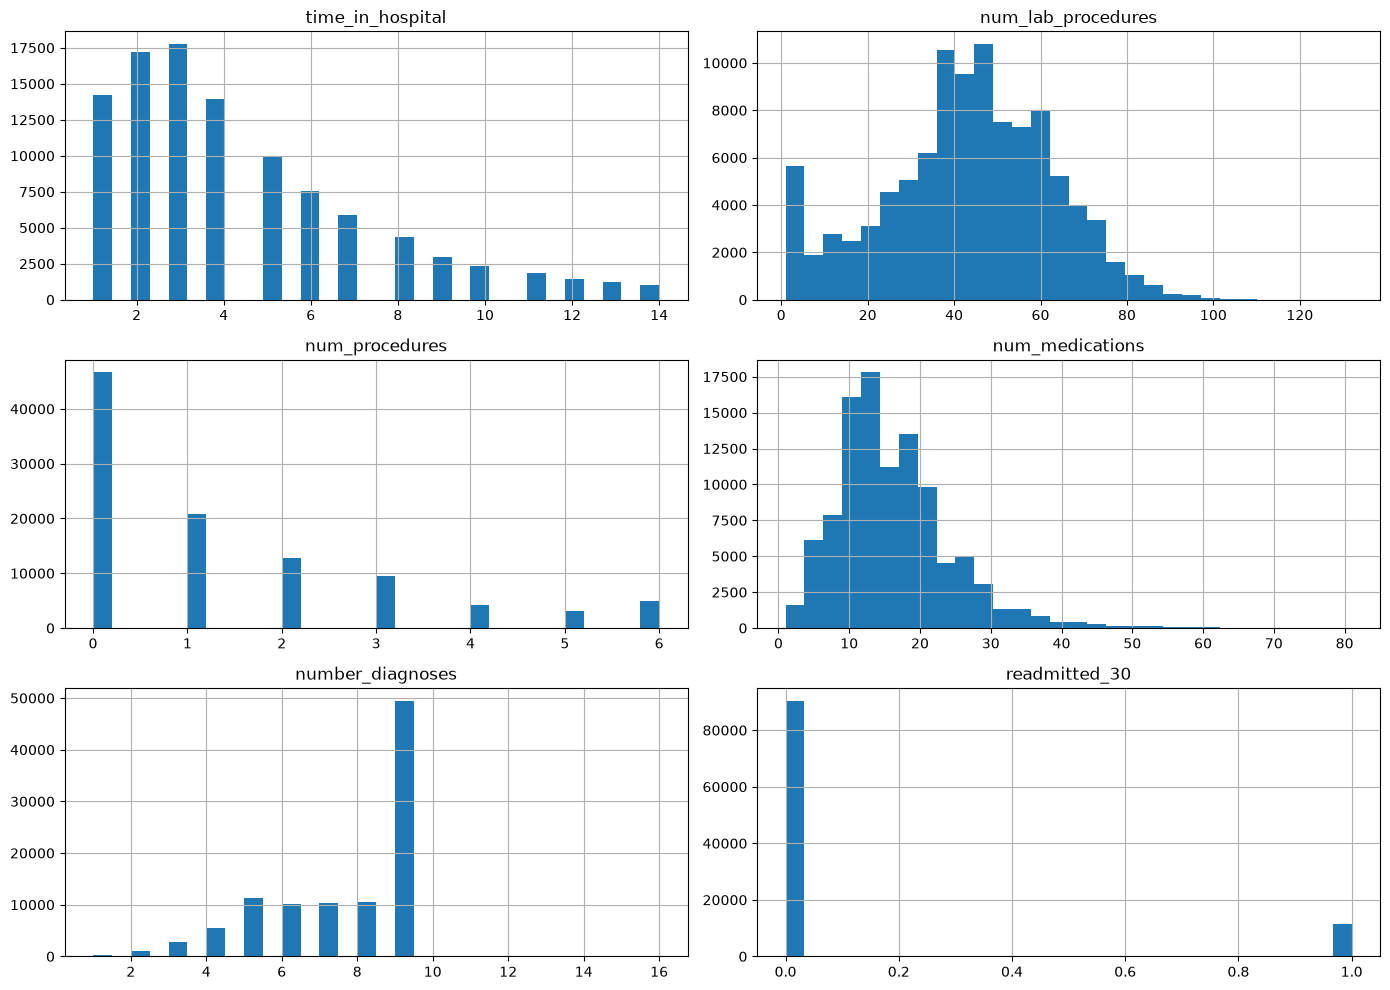

In [91]:
dtypes = df.dtypes

#Gather all numerical columns into a list
numeric_col = []

i = 0 
while i < len(dtypes):
    if dtypes.iloc[i] == 'int64':
        numeric_col.append(dtypes.index[i])
    i = i + 1


#Find the skewness for all numberical columns
skewness = df[numeric_col].skew()

print(skewness)

#number_outpatient, number_emergency, number_inpatient are skewed to the right. 
#We will plot them in bar graph, use log scale in order to visulize tails, otherwise they will be too small in regular scale. 

#Number of emergency visits of the patient in the year preceding the encounter
counts_ev = df["number_emergency"].value_counts().sort_index()

print('Emergency visits distribution', df["number_emergency"].describe(percentiles=[.5, .9, .95, .99]))

ev_plot = counts_ev.plot(kind="bar", figsize=(9, 5))
ev_plot.set_yscale("log")
ev_plot.set_xlabel("Number of emergency visits in prior year")
ev_plot.set_ylabel("Number of people (log scale)")
ev_plot.set_title("Emergency Visits")
plt.show()

#Outpatients means they do not stay overnight. This counts # of outpatient visits of the patient in the year preceding the encounter.
counts_outpatient = df["number_outpatient"].value_counts().sort_index()

outpatients_plot = counts_outpatient.plot(kind="bar", figsize=(9, 5))
outpatients_plot.set_yscale("log")
outpatients_plot.set_xlabel("Number of outpatient visits in prior year")
outpatients_plot.set_ylabel("Number of people (log scale)")
outpatients_plot.set_title("Number of outpatient Visits")

plt.show()

#Number of inpatient visits of the patient in the year preceding the encounter (ie over 24 hour stay). 
counts_inpatient = df["number_inpatient"].value_counts().sort_index()

inpatient_plot = counts_inpatient.plot(kind="bar", figsize=(9, 5))
inpatient_plot.set_yscale("log")
inpatient_plot.set_xlabel("Number of inpatient visits in prior year")
inpatient_plot.set_ylabel("Number of people (log scale)")
inpatient_plot.set_title("Number of inpatient visits")

plt.show()


#We can plot the nonskewed histograms.
#num_medications = Number of distinct generic names administered during the encounter.
#time_in_hositpal =	Integer number of days between admission and discharge.
#num_lab_procd: Number of lab tests performed during the encounter
#num_procedures = Number of procedures (other than lab tests) performed during the encounter
#num_diagones = Number of diagnoses entered to the system.

skewed_cols = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

nonskew_numeric_cols = [col for col in numeric_col if col not in skewed_cols]

df[nonskew_numeric_cols].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()



readmitted_30                         0             1
time_in_hospital   count   90409.000000  11357.000000
                   mean        4.349224      4.768249
                   median      4.000000      4.000000
                   std         2.976382      3.028165
num_lab_procedures count   90409.000000  11357.000000
                   mean       42.953644     44.226028
                   median     44.000000     45.000000
                   std        19.719348     19.276087
num_procedures     count   90409.000000  11357.000000
                   mean        1.347123      1.280884
                   median      1.000000      1.000000
                   std         1.714242      1.635992
num_medications    count   90409.000000  11357.000000
                   mean       15.911137     16.903143
                   median     15.000000     16.000000
                   std         8.124725      8.096696
number_outpatient  count   90409.000000  11357.000000
                   mean     

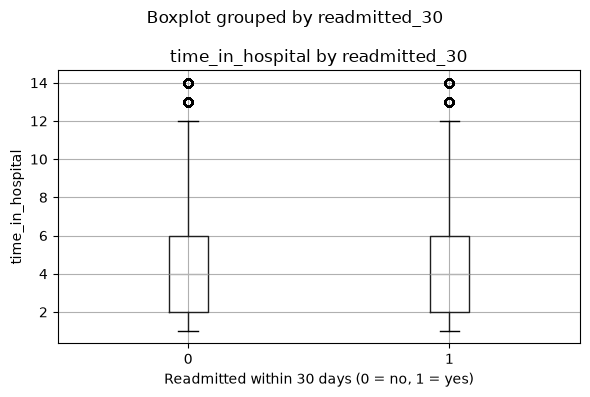

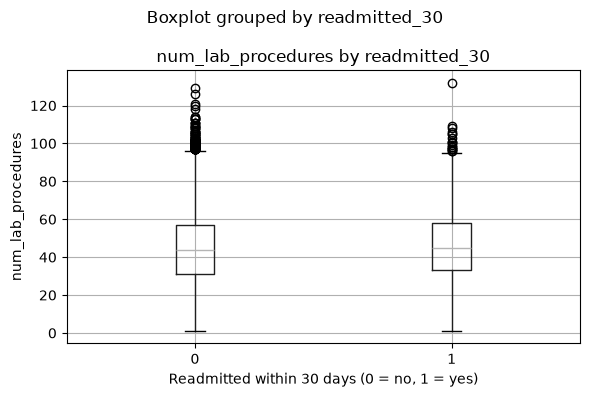

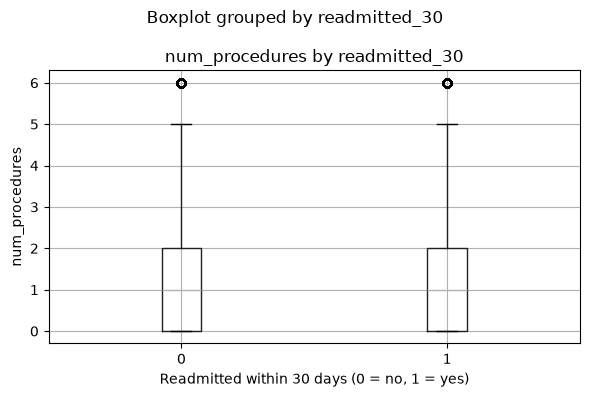

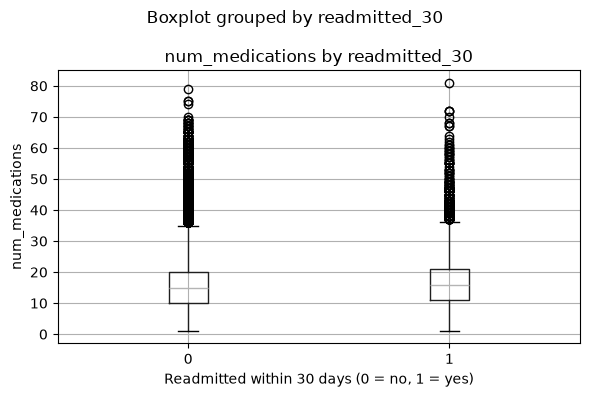

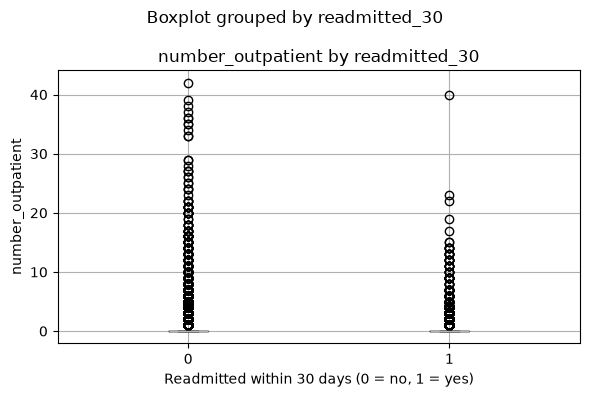

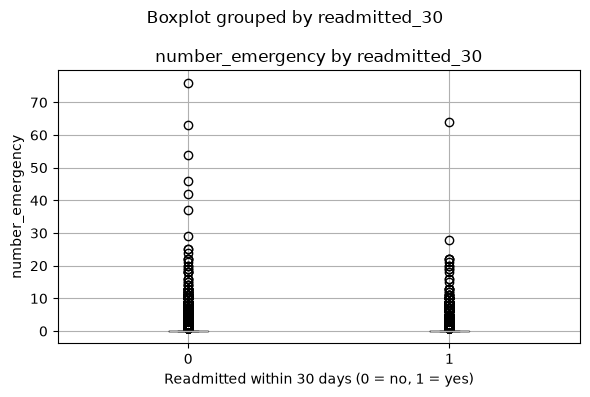

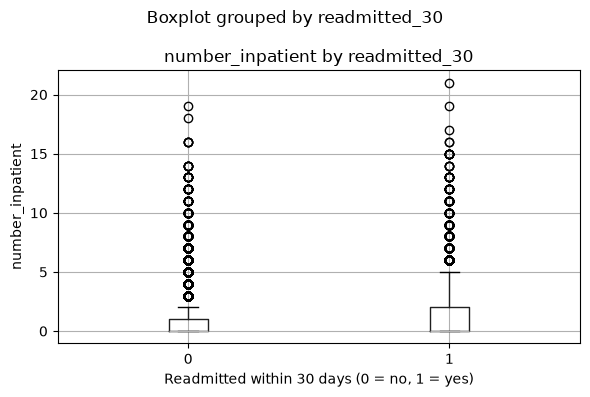

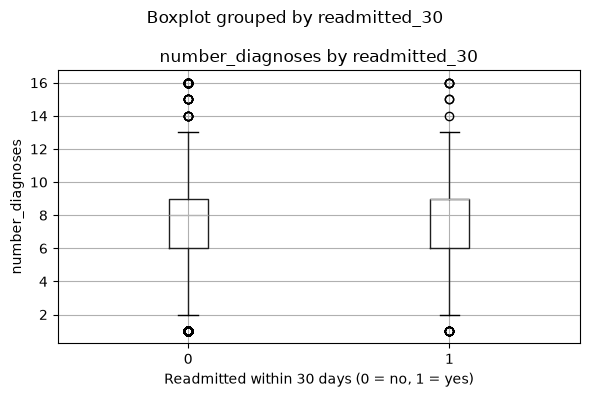

In [92]:
#Trying to see the relationship between the numeric columns and our target readmitted_30.
target = "readmitted_30"
features = [col for col in numeric_col if col != target]

numeric_col_comparison = df.groupby(target)[features].agg(
    ["count", "mean", "median", "std"]
)

print(numeric_col_comparison.T)

#The only thing that seems to stand out are the three means in number_outpatient, number_emergency, and number_inpatient. The other means
#are similar across the two groups. 


#Just plotting them out. 
for col in features:
    ax = df.boxplot(column=col, by=target, figsize=(6, 4))
    ax.set_title(f"{col} by {target}")
    ax.set_xlabel("Readmitted within 30 days (0 = no, 1 = yes)")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()


In [93]:
#Spearman correlation. To see if the numeric columns have a monotonic relationship.

correlations = df[numeric_col].corr(method = 'spearman')
correlations.round(3)




,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted_30
time_in_hospital,1.000,0.337,0.187,0.465,-0.013,-0.001,0.092,0.237,0.051
num_lab_procedures,0.337,1.000,0.023,0.252,-0.024,0.006,0.041,0.169,0.021
num_procedures,0.187,0.023,1.000,0.352,-0.024,-0.046,-0.064,0.067,-0.006
num_medications,0.465,0.252,0.352,1.000,0.074,0.044,0.099,0.294,0.045
number_outpatient,-0.013,-0.024,-0.024,0.074,1.000,0.177,0.156,0.113,0.034
number_emergency,-0.001,0.006,-0.046,0.044,0.177,1.000,0.222,0.092,0.063
number_inpatient,0.092,0.041,-0.064,0.099,0.156,0.222,1.000,0.136,0.138
number_diagnoses,0.237,0.169,0.067,0.294,0.113,0.092,0.136,1.000,0.047
readmitted_30,0.051,0.021,-0.006,0.045,0.034,0.063,0.138,0.047,1.000


In [ ]:
#Want to look more at the three numerical columns which seemed to have strong mean differece between target group 0 and 1. 

visit_cols = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

#I want to seperate these values into bins. Recall that for these three columns, the median was zero, so most people did not have visits 
#the years before. 
for col in visit_cols:
    visit_group = pd.cut(
        df[col],
        #Seperates the bins into (-\infty, 0], (0,1], (1,\infty), we can be more percise about further splits if needed but we want to
        # be careful, since there might only be few patients with 5+ visits ,etc. 
        bins=[-np.inf, 0, 1, np.inf],
        labels=["0 visits", "1 visit", "2+ visits"]
    )

    results = (
        df.assign(visit_group=visit_group)
          .groupby("visit_group", observed=False)[target]
          .agg(patients="size", readmission_rate="mean")
    )

    results["readmission_rate_pct"] = results["readmission_rate"] * 100

    print(f"\n{col}")
    print(results[["patients", "readmission_rate_pct"]])
    #We can see a clear difference between the readmittance rate between the groups. However, we need be careful that there is not
    #too much double count in the bins, ie. What if someone with 2+ invisits also has 2+ outvisits, emergencies, etc. 
    #Need to investiagate this more. 



number_outpatient
             patients  readmission_rate_pct
visit_group                                
0 visits        85027             10.674256
1 visit          8547             13.923014
2+ visits        8192             13.317871

number_emergency
             patients  readmission_rate_pct
visit_group                                
0 visits        90383             10.474315
1 visit          7677             14.354566
2+ visits        3706             21.262817

number_inpatient
             patients  readmission_rate_pct
visit_group                                
0 visits        67630              8.437084
1 visit         19521             12.924543
2+ visits       14615             21.402668


In [ ]:
#Want to see how the categorical data gives for readmittance

categorical_cols = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Exclude the target if it happens to be included
categorical_cols = [col for col in categorical_cols if col not in ['encounter_id', 'patient_nbr', 'readmitted']]

print("Overall readmission rate:", df[target].mean() * 100, "%")

for col in categorical_cols:
    results = (
        df.groupby(col, dropna=False, observed=True)[target]
          .agg(encounters="size", readmission_rate="mean")
          .sort_values("encounters", ascending=False)
    )

    results["readmission_rate_pct"] = results["readmission_rate"] * 100

    print(f"\n{col}")
    print(results[["encounters", "readmission_rate_pct"]])

    #Out of the ones which have a reasonable sample size, diabetesMed of couse is the one that strieks out. 11.62% read vs 9.5% readmit when
    #not on diabetes med. metformin Also is a good one that has impact.  As for the other categorial variables, either their readmit % is 
    #same acroos different values or the sample size is too small. 

Overall readmission rate: 11.159915885462727 %

race
                 encounters  readmission_rate_pct
race                                             
Caucasian             76099             11.290556
AfricanAmerican       19210             11.218116
NaN                    2273              8.271007
Hispanic               2037             10.407462
Other                  1506              9.628154
Asian                   641             10.140406

gender
                 encounters  readmission_rate_pct
gender                                           
Female                54708             11.245156
Male                  47055             11.061524
Unknown/Invalid           3              0.000000

age
          encounters  readmission_rate_pct
age                                       
[70-80)        26068             11.773055
[60-70)        22483             11.128408
[50-60)        17256              9.666203
[80-90)        17197             12.083503
[40-50)         9685      